#Part 1 – Read and understand the data

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

flights = pd.read_csv("data/flights.csv")
airports = pd.read_csv("data/airports.csv")

In [132]:
#Display the datasets
display(flights.head())
display(airports.head())

,date,delay,distance,origin,destination,iata,name,city,state,country,latitude,longitude,weekday,month,delay_status
0,2001-01-01,66,1750,DTW,LAS,DTW,Detroit Metropolitan-Wayne County,Detroit,MI,USA,42.212059,-83.348836,Monday,January,Delayed
1,2001-01-01,95,2399,HNL,SFO,HNL,Honolulu International,Honolulu,HI,USA,21.318691,-157.922407,Monday,January,Delayed
2,2001-01-01,-5,407,LAS,OAK,LAS,McCarran International,Las Vegas,NV,USA,36.080361,-115.152333,Monday,January,Not delayed
3,2001-01-01,4,256,LAS,PHX,LAS,McCarran International,Las Vegas,NV,USA,36.080361,-115.152333,Monday,January,Delayed
4,2001-01-01,-6,377,MHT,BWI,MHT,Manchester,Manchester,NH,USA,42.934516,-71.437056,Monday,January,Not delayed


,iata,name,city,state,country,latitude,longitude
0,00M,Thigpen,Bay Springs,MS,USA,31.953765,-89.234505
1,00R,Livingston Municipal,Livingston,TX,USA,30.685861,-95.017928
2,00V,Meadow Lake,Colorado Springs,CO,USA,38.945749,-104.569893
3,01G,Perry-Warsaw,Perry,NY,USA,42.741347,-78.052081
4,01J,Hilliard Airpark,Hilliard,FL,USA,30.688012,-81.905944


In [93]:
#Check dimensions
print("Flights:", flights.shape)
print("Airports:", airports.shape)

Flights: (20000, 5)
Airports: (3376, 7)


In [94]:
#check the data types and missing values
flights.info()
airports.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   date         20000 non-null  str  
 1   delay        20000 non-null  int64
 2   distance     20000 non-null  int64
 3   origin       20000 non-null  str  
 4   destination  20000 non-null  str  
dtypes: int64(2), str(3)
memory usage: 781.4 KB
<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   iata       3376 non-null   str    
 1   name       3376 non-null   str    
 2   city       3364 non-null   str    
 3   state      3364 non-null   str    
 4   country    3376 non-null   str    
 5   latitude   3376 non-null   float64
 6   longitude  3376 non-null   float64
dtypes: float64(2), str(5)
memory usage: 184.8 KB


In [95]:
# check the column names
print(flights.columns)
print(airports.columns)

Index(['date', 'delay', 'distance', 'origin', 'destination'], dtype='str')
Index(['iata', 'name', 'city', 'state', 'country', 'latitude', 'longitude'], dtype='str')


In [96]:
## 1. Read and understand the data

## Each row in the flights dataset represents a flight record.

## The main columns used in this analysis are date, delay,
## distance, origin and destination.

## The airports dataset provides additional information
## about airport names, cities, states and countries.

##Part 2 – Clean the data

In [97]:
flights_raw = flights.copy()
airports_raw = airports.copy()

In [98]:
print("Before:", flights["date"].dtype)

flights["date"] = pd.to_datetime(
    flights["date"], errors="coerce"
)

print("After:", flights["date"].dtype)
print("Rows processed:", len(flights))
print("Invalid dates:", flights["date"].isna().sum())

Before: str
After: datetime64[us]
Rows processed: 20000
Invalid dates: 0


In [99]:
duplicate_count = flights.duplicated().sum()

print("Duplicate records:", duplicate_count)

display(
    flights[flights.duplicated(keep=False)]
)

Duplicate records: 28


,date,delay,distance,origin,destination
541,2001-01-03,19,543,PDX,OAK
626,2001-01-03,19,543,PDX,OAK
768,2001-01-04,-18,606,ORD,ATL
898,2001-01-04,-18,606,ORD,ATL
1596,2001-01-08,5,410,STL,CMH
1705,2001-01-08,5,410,STL,CMH
1843,2001-01-09,3,641,DFW,DEN
2016,2001-01-09,3,641,DFW,DEN
2053,2001-01-10,-8,1123,DEN,DTW
2101,2001-01-10,-8,1123,DEN,DTW


In [100]:
duplicate_airports = airports[
    airports.duplicated(subset="iata", keep=False)
]

display(duplicate_airports)

,iata,name,city,state,country,latitude,longitude
47,0.00E+00,Moriarty,Moriarty,NM,USA,34.985606,-106.009466
48,0.00E+00,Crownpoint,Crownpoint,NM,USA,35.717659,-108.201596


In [101]:
invalid_distance = flights["distance"] <= 0

print("Invalid distances:", invalid_distance.sum())

display(flights[invalid_distance])

Invalid distances: 0


,date,delay,distance,origin,destination


In [102]:
for column in ["origin", "destination"]:

    cleaned = flights[column].str.strip().str.upper()

    print(column, "affected rows:",
          (flights[column] != cleaned).sum())

    flights[column] = cleaned

origin affected rows: 0
destination affected rows: 0


In [103]:
invalid_codes = ~airports["iata"].str.fullmatch(
    r"[A-Z0-9]{3,4}", na=False
)

display(airports[invalid_codes])

print("Invalid airport codes:", invalid_codes.sum())

airports = airports.loc[~invalid_codes].copy()

print("Remaining airports:", len(airports))

,iata,name,city,state,country,latitude,longitude
47,0.00E+00,Moriarty,Moriarty,NM,USA,34.985606,-106.009466
48,0.00E+00,Crownpoint,Crownpoint,NM,USA,35.717659,-108.201596


Invalid airport codes: 2
Remaining airports: 3374


In [104]:
cleaned_names = airports["name"].str.replace(
    r"\s+", " ", regex=True
).str.strip()

print("Affected rows:",
      (airports["name"] != cleaned_names).sum())

airports["name"] = cleaned_names

Affected rows: 12


#Part 3 – Handle missing values

In [105]:
print("Missing values in flights:")
print(flights.isnull().sum())

print("Missing values in airports:")
print(airports.isnull().sum())

Missing values in flights:
date           0
delay          0
distance       0
origin         0
destination    0
dtype: int64
Missing values in airports:
iata          0
name          0
city         12
state        12
country       0
latitude      0
longitude     0
dtype: int64


In [106]:
print(flights.isnull().mean() * 100)

print(airports.isnull().mean() * 100)

date           0.0
delay          0.0
distance       0.0
origin         0.0
destination    0.0
dtype: float64
iata         0.000000
name         0.000000
city         0.355661
state        0.355661
country      0.000000
latitude     0.000000
longitude    0.000000
dtype: float64


In [107]:
print("Missing city:", airports["city"].isna().sum())
print("Missing state:", airports["state"].isna().sum())

airports["city"] = airports["city"].fillna("Unknown")
airports["state"] = airports["state"].fillna("Unknown")

Missing city: 12
Missing state: 12


In [108]:
print(airports.isnull().sum())

iata         0
name         0
city         0
state        0
country      0
latitude     0
longitude    0
dtype: int64


#### Missing value decisions

City:
Missing city values were replaced with "Unknown"
because the correct city cannot be determined
from the available information.

State:
Missing state values were replaced with "Unknown"
to preserve airport records without inventing locations.

Missing information may indicate unavailable or
unrecorded geographical details.

#Part 4 – Merge with the second table

In [109]:
#Merge the flights dataset with the airports dataset using origin and iata.
before_merge = len(flights)

flights = flights.merge(
    airports,
    left_on="origin",
    right_on="iata",
    how="left",
    validate="many_to_one",
    indicator=True
)

after_merge = len(flights)

In [110]:
#Validate the merge
print("Before merge:", before_merge)
print("After merge:", after_merge)
print("Difference:", after_merge - before_merge)

print(flights["_merge"].value_counts())

assert before_merge == after_merge

Before merge: 20000
After merge: 20000
Difference: 0
_merge
both          20000
left_only         0
right_only        0
Name: count, dtype: int64


In [111]:
flights = flights.drop(columns=["_merge"])

display(flights.head())

,date,delay,distance,origin,destination,iata,name,city,state,country,latitude,longitude
0,2001-01-01,66,1750,DTW,LAS,DTW,Detroit Metropolitan-Wayne County,Detroit,MI,USA,42.212059,-83.348836
1,2001-01-01,95,2399,HNL,SFO,HNL,Honolulu International,Honolulu,HI,USA,21.318691,-157.922407
2,2001-01-01,-5,407,LAS,OAK,LAS,McCarran International,Las Vegas,NV,USA,36.080361,-115.152333
3,2001-01-01,4,256,LAS,PHX,LAS,McCarran International,Las Vegas,NV,USA,36.080361,-115.152333
4,2001-01-01,-6,377,MHT,BWI,MHT,Manchester,Manchester,NH,USA,42.934516,-71.437056


##Part 5 – Create new columns

In [112]:
#Weekday
flights["weekday"] = flights["date"].dt.day_name()

In [113]:
flights["month"] = flights["date"].dt.month_name()

In [114]:
flights["delay_status"] = np.where(
    flights["delay"] > 0,
    "Delayed",
    "Not delayed"
)

In [115]:
flights[[
    "date",
    "weekday",
    "month",
    "delay",
    "delay_status"
]].head(10)

,date,weekday,month,delay,delay_status
0,2001-01-01,Monday,January,66,Delayed
1,2001-01-01,Monday,January,95,Delayed
2,2001-01-01,Monday,January,-5,Not delayed
3,2001-01-01,Monday,January,4,Delayed
4,2001-01-01,Monday,January,-6,Not delayed
5,2001-01-01,Monday,January,-27,Not delayed
6,2001-01-01,Monday,January,-7,Not delayed
7,2001-01-01,Monday,January,-26,Not delayed
8,2001-01-01,Monday,January,29,Delayed
9,2001-01-01,Monday,January,-4,Not delayed


##Part 6 – Group and compare

In [116]:
airport_summary = flights.groupby(
    ["origin", "name"]
).agg(
    average_delay=("delay", "mean"),
    median_delay=("delay", "median"),
    flight_count=("delay", "count")
)

airport_summary = airport_summary.round(2)

display(airport_summary.head(10))

,,average_delay,median_delay,flight_count
origin,name,,,
ABE,Lehigh Valley International,-5.00,-5.5,8
ABI,Abilene Regional,0.40,0.0,5
ABQ,Albuquerque International,8.35,0.0,123
ACT,Waco Regional,3.83,0.5,6
ALB,Albany Cty,2.70,-5.5,54
AMA,Amarillo International,2.90,-1.0,21
ANC,Ted Stevens Anchorage International,11.83,6.5,58
APF,Naples Municipal,-9.00,-9.0,1
ATL,William B Hartsfield-Atlanta Intl,7.81,0.0,846


In [117]:
#Average delay by weekday
weekday_summary = flights.groupby("weekday").agg(
    average_delay=("delay", "mean"),
    median_delay=("delay", "median"),
    flight_count=("delay", "count")
)

display(weekday_summary.round(2))

,average_delay,median_delay,flight_count
weekday,,,
Friday,11.76,3.0,3003
Monday,7.07,-1.0,2952
Saturday,4.21,-2.0,2655
Sunday,6.97,-1.0,2648
Thursday,9.30,1.0,2944
Tuesday,7.18,0.0,2903
Wednesday,6.91,0.0,2895


In [118]:
#Average delay by month
monthly_summary = flights.groupby("month").agg(
    average_delay=("delay", "mean"),
    flight_count=("delay", "count")
)

display(monthly_summary.round(2))

,average_delay,flight_count
month,,
February,9.60,5964
January,6.44,6937
March,7.35,7099


#Part 7 – Describe with numbers

In [119]:
#Descriptive statistics
flights["delay"].describe()

count    20000.000000
mean         7.703900
std         31.318537
min        -59.000000
25%         -8.000000
50%          0.000000
75%         13.000000
max        522.000000
Name: delay, dtype: float64

In [120]:
#Middle and spread
print("Mean:", flights["delay"].mean())
print("Median:", flights["delay"].median())
print("Standard deviation:", flights["delay"].std())
print("Minimum:", flights["delay"].min())
print("Maximum:", flights["delay"].max())
print("Range:", flights["delay"].max()
      - flights["delay"].min())

Mean: 7.7039
Median: 0.0
Standard deviation: 31.318537119865073
Minimum: -59
Maximum: 522
Range: 581


In [121]:
#Outlier investigation
Q1 = flights["delay"].quantile(0.25)
Q3 = flights["delay"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = flights[
    (flights["delay"] < lower_bound) |
    (flights["delay"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Total outliers:", len(outliers))

Q1: -8.0
Q3: 13.0
IQR: 21.0
Lower bound: -39.5
Upper bound: 44.5
Total outliers: 1703


In [122]:
#Compare distance and delay
correlation = flights["distance"].corr(
    flights["delay"]
)

print("Correlation:", round(correlation, 3))

Correlation: -0.022


#Part 8 – Data visualisation

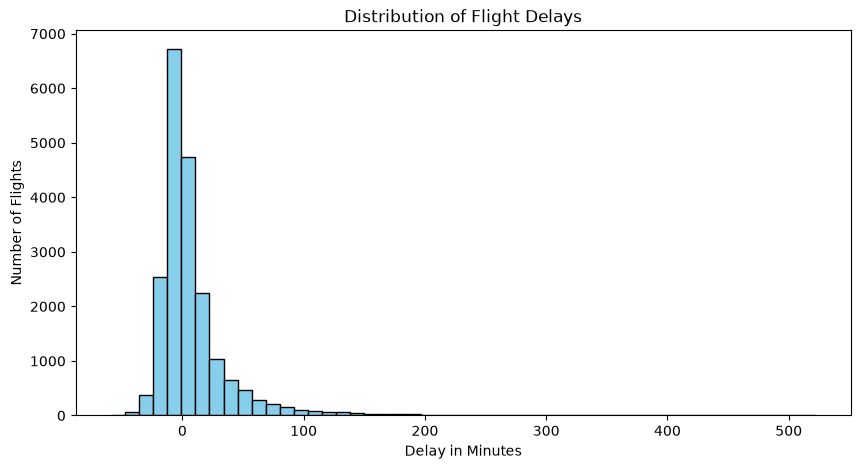

In [123]:
plt.figure(figsize=(10, 5))

plt.hist(
    flights["delay"],
    bins=50,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Flight Delays")
plt.xlabel("Delay in Minutes")
plt.ylabel("Number of Flights")
plt.show()

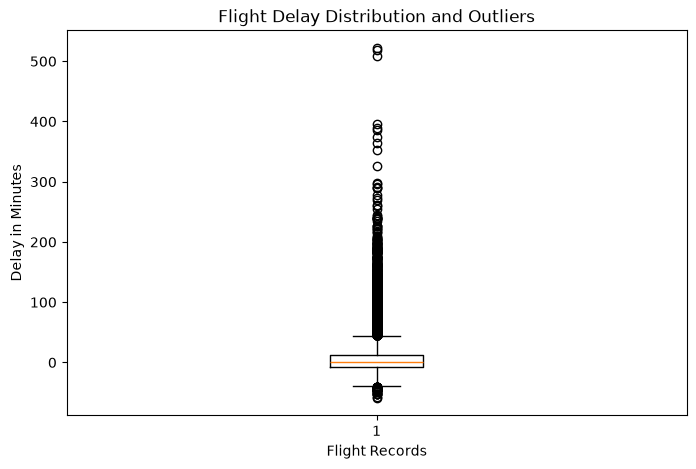

In [124]:
#Boxplot
plt.figure(figsize=(8, 5))

plt.boxplot(flights["delay"].dropna())

plt.title("Flight Delay Distribution and Outliers")
plt.xlabel("Flight Records")
plt.ylabel("Delay in Minutes")
plt.show()

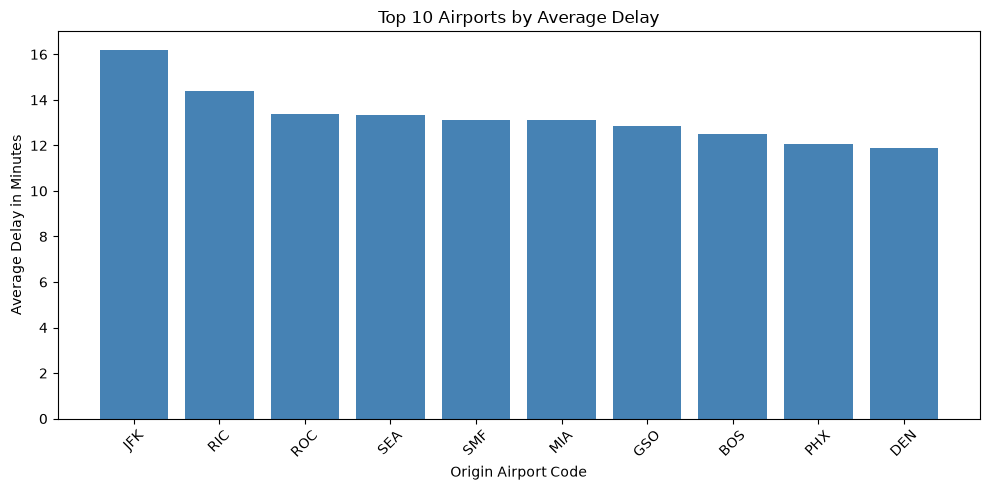

In [125]:
#Bar chart
#Select airports with at least 30 flight records to reduce the influence of very small groups.
top_airports = airport_summary[
    airport_summary["flight_count"] >= 30
].sort_values(
    "average_delay",
    ascending=False
).head(10)

top_airports = top_airports.reset_index()

plt.figure(figsize=(10, 5))

plt.bar(
    top_airports["origin"],
    top_airports["average_delay"],
    color="steelblue"
)

plt.title("Top 10 Airports by Average Delay")
plt.xlabel("Origin Airport Code")
plt.ylabel("Average Delay in Minutes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

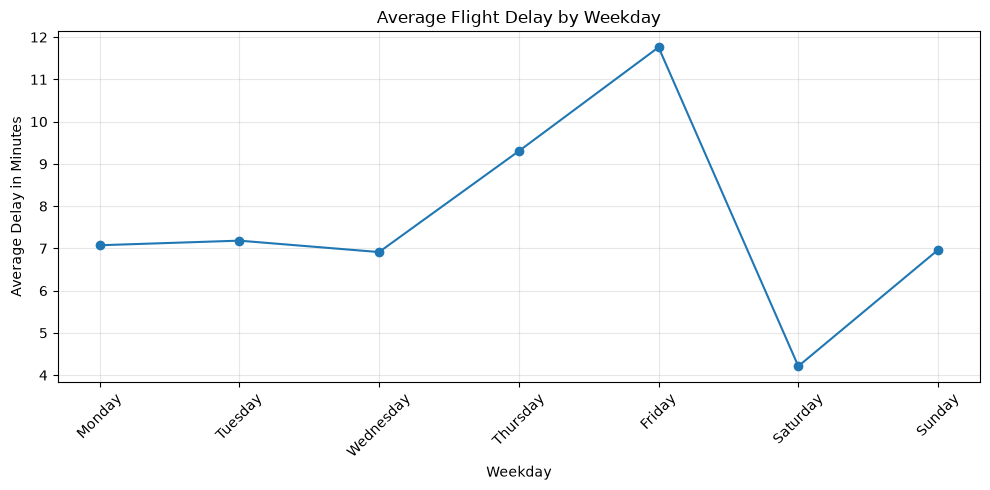

In [126]:
#Line Chart
#Weekday average delay line chart
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_delays = flights.groupby(
    "weekday"
)["delay"].mean().reindex(weekday_order)

plt.figure(figsize=(10, 5))

plt.plot(
    weekday_delays.index,
    weekday_delays.values,
    marker="o"
)

plt.title("Average Flight Delay by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Delay in Minutes")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

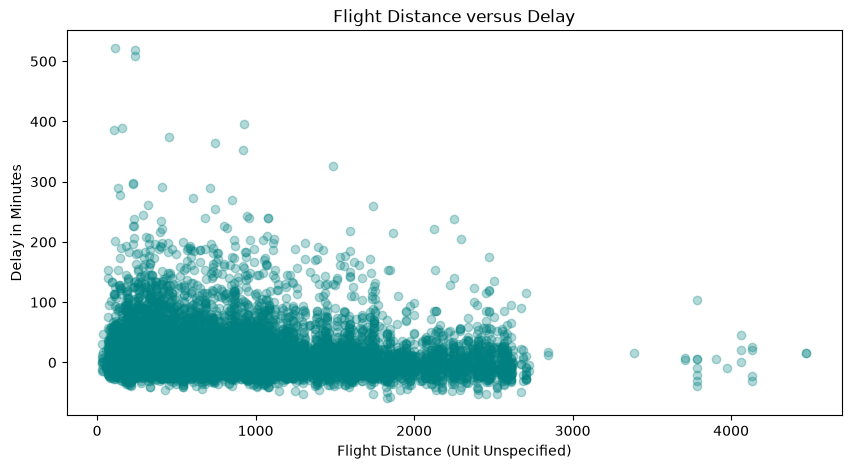

In [127]:
#Scatter Plot
plt.figure(figsize=(10, 5))

plt.scatter(
    flights["distance"],
    flights["delay"],
    alpha=0.3,
    color="teal"
)

plt.title("Flight Distance versus Delay")
plt.xlabel("Flight Distance (Unit Unspecified)")
plt.ylabel("Delay in Minutes")
plt.show()

In [128]:
#Part 9 – Answer your research questions
display(top_airports[[
    "origin",
    "name",
    "average_delay",
    "median_delay",
    "flight_count"
]])


,origin,name,average_delay,median_delay,flight_count
0,JFK,John F Kennedy Intl,16.20,3.0,200
1,RIC,Richmond International,14.40,-0.5,50
2,ROC,Greater Rochester Int'l,13.38,3.5,58
3,SEA,Seattle-Tacoma Intl,13.34,2.0,339
4,SMF,Sacramento International,13.12,4.0,121
5,MIA,Miami International,13.12,4.0,294
6,GSO,Piedmont Triad International,12.86,-1.0,57
7,BOS,Gen Edw L Logan Intl,12.52,2.0,369
8,PHX,Phoenix Sky Harbor International,12.05,4.0,633
9,DEN,Denver Intl,11.90,1.0,452


In [129]:
#Which weekday has the highest average delay?
print("Highest delay weekday:", weekday_delays.idxmax())
print("Average delay:", weekday_delays.max())

print("Lowest delay weekday:", weekday_delays.idxmin())
print("Average delay:", weekday_delays.min())

print("Difference:",
      weekday_delays.max() - weekday_delays.min())

Highest delay weekday: Friday
Average delay: 11.75990675990676
Lowest delay weekday: Saturday
Average delay: 4.212052730696798
Difference: 7.5478540292099625


In [130]:
#Is flight distance associated with longer delays?
correlation = flights["distance"].corr(
    flights["delay"]
)

print("Correlation coefficient:", correlation)

Correlation coefficient: -0.021706789811706678


#Part 9 – Answer your research questions

In [ ]:
airport_summary = merged_flights.groupby("origin").agg(
    average_delay=("delay", "mean"),
    median_delay=("delay", "median"),
    flight_count=("delay", "count")
)

top_airports = airport_summary[
    airport_summary["flight_count"] >= 30
].sort_values("average_delay", ascending=False).head(10)

display(top_airports.round(2))

#Write your findings using this Markdown format:
### Research Question 1

Question:

Numerical evidence:

Chart reference:

Interpretation:

Conclusion:

#Part 10 – Check the data and the source

In [ ]:
#Dataset coverage
print("Earliest date:", flights["date"].min())
print("Latest date:", flights["date"].max())

print("Unique dates:", flights["date"].nunique())

print("Origin airports:", flights["origin"].nunique())

print("Destination airports:",
      flights["destination"].nunique())

Earliest date: 2001-01-01 00:00:00
Latest date: 2001-03-31 00:00:00
Unique dates: 90
Origin airports: 220
Destination airports: 223


In [ ]:
#Check original missing information
print("Original flight data missing values:")
print(flights_raw.isnull().sum())

print("Original airport data missing values:")
print(airports_raw.isnull().sum())

Original flight data missing values:
date           0
delay          0
distance       0
origin         0
destination    0
dtype: int64
Original airport data missing values:
iata          0
name          0
city         12
state        12
country       0
latitude      0
longitude     0
dtype: int64


In [ ]:
#Compare original and cleaned datasets
print("Original flight records:", len(flights_raw))
print("Final flight records:", len(flights))

print("Original airport records:", len(airports_raw))
print("Cleaned airport records:", len(airports))

Original flight records: 20000
Final flight records: 20000
Original airport records: 3376
Cleaned airport records: 3374


### Data Source and Limitations

### Data source
[Identify and verify the original data provider.]

### Time period
The dataset covers January to March 2001.

### Missing information
The dataset does not contain flight identifiers,
airline names, delay causes or meaningful flight times.

### Data reliability
The airport dataset contains malformed airport codes
and missing geographical information.

### Limitations
The distance measurement unit is not documented
in the supplied assignment.

Identical flight records cannot be confirmed as
duplicates because unique flight identifiers
are unavailable.

The dataset cannot establish the actual causes
of flight delays.

### Unsupported claim
These historical records cannot be used to claim
that a particular airport is currently the worst
airport for flight delays.